# Regularización: weight decay con AdamW en la RNN bidireccional

¿Cuánto weight decay conviene?

AdamW achica los pesos en cada paso, aparte del paso de Adam: `w ← w − lr · λ · w`. Penaliza los pesos
grandes (como L2) y empuja a la red a soluciones más simples. A diferencia de `Adam(weight_decay=λ)`, el
decay no pasa por la escala adaptativa de Adam, así que todos los pesos se regularizan por igual.

**Rango de valores**: el decay de cada paso es `lr · λ`. Con `lr = 1e-3` y ~300 pasos (15 épocas), los
pesos se achican en total un factor ≈ `exp(−lr · λ · pasos)`: con λ = 0.1 apenas un 3%, con λ = 1 un ~25%.
Por eso la grilla llega hasta 1. Valores típicos de los papers (1e-4 a 1e-2) casi no cambian nada con este
`lr` y tan pocos pasos.

Se entrena solo `bidirectional_rnn` (capitalización y puntuación) una vez por valor de `λ`, con los
mismos datos, splits, semilla y épocas que el pipeline. `λ = 0` es exactamente Adam.

**En Colab**: Entorno de ejecución → Cambiar tipo de entorno de ejecución → **GPU**, y que la rama
`feat/regularizacion` esté pusheada.

## 1. Setup

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
BRANCH = "feat/regularizacion"  # rama con src/regularization.py
REPO = "/content/TP2-Aprendizaje-Automatico-UBA"

if IN_COLAB:
    # Los resultados van a Drive: la máquina de Colab se borra al cerrar la sesión
    from google.colab import drive
    drive.mount("/content/drive")
    if not Path(REPO).exists():
        !git clone https://github.com/SebasAndres/TP2-Aprendizaje-Automatico-UBA.git {REPO}
    %cd {REPO}
    !git fetch origin && git checkout {BRANCH} && git pull
    !pip install -q uv && uv sync
    !mkdir -p /content/drive/MyDrive/tp2-models
    !if [ ! -L models ]; then rm -rf models && ln -s /content/drive/MyDrive/tp2-models models; fi
else:
    # Local: el notebook corre desde notebooks/, subimos hasta la raíz del repo
    while not Path("pyproject.toml").exists():
        os.chdir("..")
print("Directorio:", Path.cwd())

Directorio: /content/TP2-Aprendizaje-Automatico-UBA


## 2. Barrido

In [2]:
PARAM = "weight_decay"
VALUES = [0.0, 1e-3, 1e-2, 1e-1, 0.5, 1.0]  # 0 = AdamW sin decay, igual a Adam
# Dropout fijo: 0 = sin dropout, así solo cambia el weight decay.
# Para combinarlos, poner el mejor p de regularization_dropout.ipynb
DROPOUT = 0.0

# Con pocas épocas no llega a sobreajustar y no se ve el efecto de la regularización
EPOCHS = 15
# Instancias por fuente (default del pipeline: 1000). Más datos = más lento
CAPITALIZATION_SIZE = 1000
PUNCTUATION_SIZE = 1000

In [5]:
VALUES_ARG = " ".join(str(v) for v in VALUES)
!MPLBACKEND=Agg uv run python -m src.regularization --param weight_decay --values {VALUES_ARG} --dropout {DROPOUT} \
    --epochs {EPOCHS} --capitalization-size {CAPITALIZATION_SIZE} --punctuation-size {PUNCTUATION_SIZE}

2026-11-16 19:03:05,666 INFO src.data.preprocess: Fuente tatoeba: 1000 instancias
2026-11-16 19:03:05,678 INFO src.data.preprocess: Fuente rioplatense: 1000 instancias
2026-11-16 19:03:05,686 INFO src.data.preprocess: Fuente ted: 1000 instancias
2026-11-16 19:03:05,691 INFO src.data.preprocess: Fuente mrbeast: 1000 instancias
2026-11-16 19:03:05,697 INFO src.data.preprocess: Fuente peliculas: 1000 instancias
2026-11-16 19:03:05,707 INFO src.data.preprocess: Fuente simuladores: 1000 instancias
2026-11-16 19:03:05,715 INFO src.data.preprocess: Fuente okupas: 1000 instancias
2026-11-16 19:03:06,110 WARNING huggingface_hub.utils._http: Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.



2026-11-16 19:03:08,550 INFO src.data.preprocess: Fuente tatoeba: 1000 instancias
2026-11-16 19:03:08,562 INFO src.data.preprocess: Fuente rioplatense: 1000 instancias
2026-11-16 19:03:08,569 INFO src.data.preprocess: F

## 3. Resultados

In [6]:
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

from src.regularization_plots import (
    best_value,
    latest_results,
    load_results,
    plot_control_f1,
    plot_gap,
    plot_loss_curves,
    summary_table,
)

%matplotlib inline

# Apuntamos directamente a la carpeta de salida que nos arrojó el script de entrenamiento
RESULTS = Path("models/regularization/2026-11-16__19-03-16__weight_decay/results.json")
report = load_results(RESULTS)
print("Resultados:", RESULTS)
print("Configuración:", report["config"])


def show_and_save(fig, name: str) -> None:
    """Muestra el gráfico y lo guarda como PNG junto al results.json (para adjuntar al PR)"""
    fig.savefig(RESULTS.parent / f"{name}.png", dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)

Resultados: models/regularization/2026-11-16__19-03-16__weight_decay/results.json
Configuración: {'param': 'weight_decay', 'values': [0.0, 0.001, 0.01, 0.1, 0.5, 1.0], 'dropout': 0.0, 'weight_decay': 0.0, 'epochs': 15, 'capitalization_size': 1000, 'punctuation_size': 1000, 'window': {'min_size': 5, 'max_size': 60, 'distribution': 'uniform'}, 'learning_rate': 0.001, 'grad_clip_norm': 1.0}


### Tabla

Por problema y valor de `weight_decay`:

- **época**: la época con mejor F1 en test (la que se queda el entrenamiento).
- **brecha**: F1 promedio de train menos el de test en esa época. Cuanto más grande, más sobreajusta.
- **test / control**: F1 macro promedio de las tareas del problema. **Comparar con control**: test ya se
  usó para elegir la época, así que su F1 es optimista.

In [7]:
print(summary_table(report))


CapitalizationProblem
         valor           época          brecha            test         control  ctrl capitalizacion
             0              12           0.150           0.538           0.461           0.461
         0.001              12           0.149           0.538           0.461           0.461
          0.01              12           0.150           0.538           0.461           0.461
           0.1              12           0.154           0.533           0.460           0.460
           0.5              12           0.132           0.526           0.456           0.456
             1              14           0.185           0.505           0.469           0.469

PunctuationProblem
         valor           época          brecha            test         control  ctrl punt_inicial  ctrl punt_final
             0              13           0.025           0.638           0.647           0.755           0.538
         0.001              13           0.025           0.63

### F1 en control

¿Con qué `λ` generaliza mejor? Con `λ` muy grande los pesos no pueden crecer lo necesario y el F1 cae.

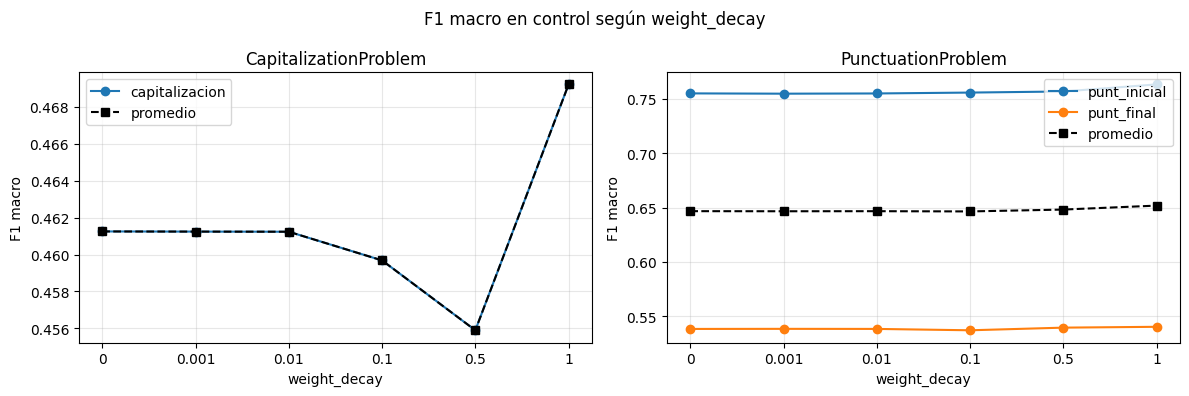

In [8]:
show_and_save(plot_control_f1(report, PARAM), "f1_control_weight_decay")

### Curvas de loss

Sin regularización, la loss de train (punteada) sigue bajando mientras la de test (llena) se estanca o
sube: la red memoriza train. Con regularización, la loss de train baja más lento y la de test debería
subir menos al final.

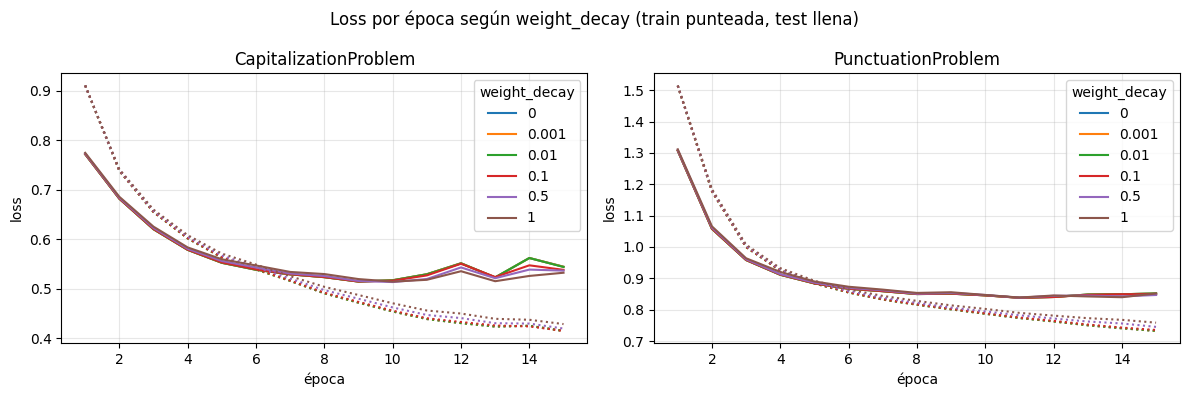

In [9]:
show_and_save(plot_loss_curves(report, PARAM), "loss_weight_decay")

### Sobreajuste

Brecha de F1 entre train y test en la mejor época. Si la regularización funciona, baja al aumentar el
valor; si baja pero el F1 de control también cae, el valor es demasiado grande (la red queda sub-ajustada).

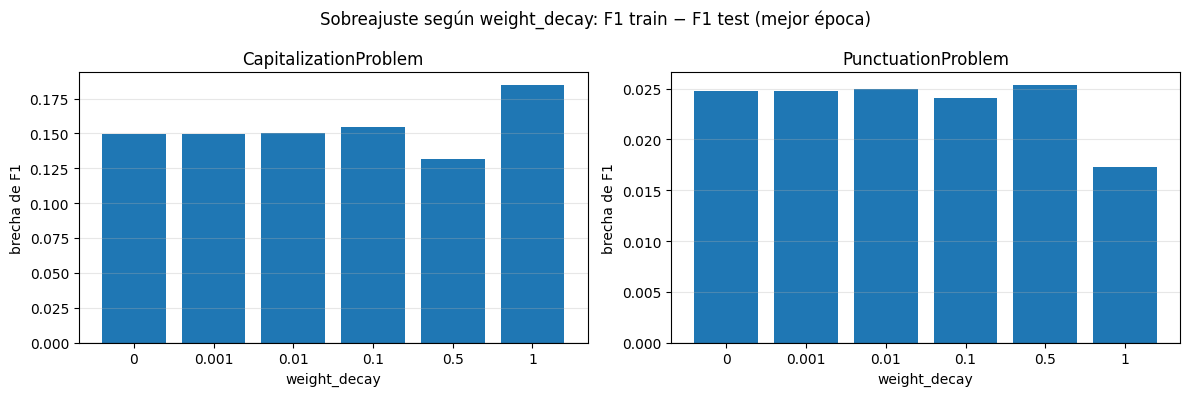

In [10]:
show_and_save(plot_gap(report, PARAM), "brecha_weight_decay")

## 4. Mejor valor por problema

In [11]:
for problem in report["problems"]:
    print(f"{problem}: {PARAM} = {best_value(report, problem):g}")

CapitalizationProblem: weight_decay = 1
PunctuationProblem: weight_decay = 1


## 5. Conclusión

El valor se elige con **test** (como la mejor época de cada red) y **control** solo confirma: si eligiéramos
mirando control, el ganador entre 6 candidatos tendría un F1 inflado por suerte y control dejaría de ser
una estimación honesta.

- **Entre λ = 0 y 0.1 no cambia nada**: con `lr = 1e-3` y ~300 pasos el decay total es < 3%.
- **Puntuación → λ = 1.** Mejor F1 en test (0.644 vs 0.638 sin decay), control va en la misma dirección
  (0.652 vs 0.647) y la brecha train−test baja (0.025 → 0.017). La mejora es chica: esta red casi no
  sobreajusta y su mejor época es de las últimas (todavía estaba aprendiendo).
- **Capitalización → λ = 0.** Con decay empeora en test (0.538 → 0.505 con λ = 1, 0.526 con λ = 0.5). λ = 0.5
  baja la brecha (0.150 → 0.132), pero porque train cae más que test, no porque generalice mejor. La suba
  en control con λ = 1 (+0.008) contradice a test: es ruido. Sí sobreajusta (brecha 0.15), pero el weight
  decay no es la herramienta que lo corrige; ver `regularization_dropout.ipynb`.

Queda en `bidirectional_rnn_weight_decay` de cada `Problem`. Las demás redes siguen con λ = 0 (Adam) hasta
probarlo en ellas: el efecto depende de la cantidad de pasos y de la arquitectura. Es una sola semilla;
diferencias de ±0.01 podrían no repetirse.
